# Project mortality impacts using the fully interacted model 
(By age, with long-run climate / GDP / pop covariates)

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import zarr
import warnings
from tqdm.notebook import tqdm
from dask.diagnostics import ProgressBar

import distributed

from funcs_support import get_filepaths,get_params,utility_save
from funcs_readregs import coeffs_mortality, coeffs_gdppc, coeffs_payroll
dir_list = get_params()

In [2]:
from distributed import Client

# Start dask client 
client = Client()
display(client)

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 33143 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc3/proxy/33143/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc3/proxy/33143/status,Workers: 6
Total threads: 18,Total memory: 72.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:40379,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc3/proxy/33143/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:37265,Total threads: 3
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc3/proxy/35641/status,Memory: 12.00 GiB
Nanny: tcp://127.0.0.1:33265,


In [3]:
#------------------------------------
# Setup -----------------------------
#------------------------------------
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','popwght':True}}
proc = 'mortality'

# Subset to only "main" specification
sp = {'resolution':'025deg','timeframe':'1980-2010','spec':'interacted','obstreat':'sep','indflag':'noInd'}

# Load Carleton et al. "Impact Regions"
with warnings.catch_warnings():
    # Ignoring a geometry warning that's not relevant here, since only
    # using this dataframe for the location codes
    warnings.filterwarnings('ignore')
    gdf = gpd.read_file(dir_list['aux']+'geo_data/impact-region.shp')

# Load interacted coefficients
coeffs,vcv = coeffs_mortality(spec='interacted',return_raw=True)

#------------------------------------
# Prep covariates -------------------
#------------------------------------
fn_covars = dir_list['proc']+'aux/all_preds_tmp.zarr'
if not os.path.exists(fn_covars):
    # Load covariates
    preds = xr.open_zarr(dir_list['proc']+'aux/all_preds.zarr')
    # Get mean across years 
    preds = preds.mean('year')
    
    # Get covariates in form for coeffs
    preds_tmp = preds[['lgdppc','lrtavg']].to_dataarray(dim='covar')
    preds_tmp = xr.concat([xr.ones_like(preds_tmp.isel(covar=0,drop=True).expand_dims({'covar':['1']})),
               preds_tmp],
              dim='covar')
    preds_tmp = preds_tmp.set_index(idv = ['model','exprun'])
    preds_tmp = preds_tmp.to_dataset(name='covars')

    preds_tmp.attrs['SOURCE'] = '3b_project_impacts_mortality_interacted.ipynb'
    preds_tmp.attrs['DESCRIPTION'] = 'covariates from all_preds.zarr broadcast, with constant, in form needed for impact projection.'
    utility_save(preds_tmp.drop_encoding().reset_index('idv'),
             fn_covars,
             zarr_mode = 'w')

# Load from file even if generating, to avoid dask issues
preds_tmp = xr.open_zarr(fn_covars)
preds_tmp = preds_tmp.set_index(idv = ['model','exprun'])
preds_tmp = preds_tmp.chunk({'hierid':1000,'idv':100})

# Get a version of the covars with constant 0.61GWL long-run temperature
preds_tmp['covars_ref'] = preds_tmp.covars.where(preds_tmp.covar != 'lrtavg',
                      preds_tmp.covars.sel(covar='lrtavg',gwl=0.61))

#------------------------------------
# Calculate interacted coefficients -
#------------------------------------
fn_interacted_coeffs = dir_list['proc']+'aux/all_covars.zarr'

if not os.path.exists(fn_interacted_coeffs):
    # Get interacted coefficients
    coeffs_interacted = (coeffs.sel(sp).chunk()*preds_tmp.covars).sum('covar',skipna=False)
    coeffs_interacted['coeffs_ref'] = (coeffs.coeffs.sel(sp).chunk()*preds_tmp.covars_ref).sum('covar',skipna=False)
    
    coeffs_interacted.attrs['SOURCE'] = '3b_project_impacts_mortality_interacted.ipynb'
    coeffs_interacted.attrs['DESCRIPTION'] = 'covars from all_preds_tmp.zarr multiplied by standard spec mortality coefficients'

    utility_save(coeffs_interacted.chunk({'idv':25}).drop_encoding().reset_index('idv'),
                 fn_interacted_coeffs,
                 zarr_mode = 'w')

# Load from file even if generating, to avoid dask issues
coeffs_interacted = xr.open_zarr(fn_interacted_coeffs)
coeffs_interacted = coeffs_interacted.set_index(idv = ['model','exprun'])

#coeffs_interacted = coeffs_interacted.chunk({'hierid':100,'idv':25})
coeffs_interacted = coeffs_interacted.chunk({'hierid':-1})


/glade/derecho/scratch/schwarzwald/tmp/ipykernel_69709/2002947709.py:50: FutureWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  preds_tmp['covars_ref'] = preds_tmp.covars.where(preds_tmp.covar != 'lrtavg',


In [8]:
overwrite = True
# Get filenames of aggregated climate predictors
fns = np.sort(glob.glob(f'{dir_list['proc']}aggs/{params_proc[proc]['varname']}_agg_*_{params_proc[proc]['geo_typ']}*.zarr'))
if params_proc[proc]['popwght']:
    fns = [fn for fn in fns if re.search(r'\_popwght\.zarr',fn)]
else:
    fns = [fn for fn in fns if not re.search(r'\_popwght\.zarr',fn)]

def project_impact(ds,coeff_var = 'coeffs'):
    ''' Helper function for xr.map_blocks
    '''
    return (ds[coeff_var]*ds.tassumpoly).sum('pred',skipna=False)

# Load covariates with population
preds = xr.open_zarr(dir_list['proc']+'aux/all_preds.zarr')
# Get pop counts by ageset
agepops_tmp = preds.pop.sel(ageset = [age for age in preds.ageset.values if age != 'agetotal']).mean('year').load().chunk({'gwl':1})


for fn in tqdm(fns):
    output_fn = f'{dir_list['proc']}impact_projs/{proc}-interacted/{re.sub(params_proc[proc]['varname'],f'd{proc}-interacted',re.split(r'\/',fn)[-1])}'
            
    if overwrite or (not os.path.exists(output_fn+'/.done')):
        #--------------------------------
        # Load climate data -------------
        #--------------------------------
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore')
            # Ignore .done flag warning
            ds = xr.open_zarr(fn,consolidated=False,decode_timedelta=False)
        
        # Make model/exprun dimension to match
        ds['exprun'] = ds['experiment']+ds['run']
        ds = ds.set_index(idv = ['model','exprun'])
        
        if params_proc[proc]['varname'] == 'tassumpoly':
            ds['degree'] = [f'tassumpoly_{k}' for k in ds.degree.values]
            ds = ds.rename({'degree':'pred'})
        elif params_proc[proc]['varname'] == 'tasmaxbinF':
            ds['binF'] = [f'tasmaxbinF_{k}' for k in ds.binF.values]
            ds = ds.rename({'binF':'pred'})
        elif params_proc[proc]['varname'] == 'days90plus':
            ds = ds.rename({'binF':'pred'})
        else:
            raise KeyError()
        
        # Set location codes as they were originally generated
        ds['poly_idx'] = gdf.hierid.values
        ds = ds.rename({'poly_idx':'hierid'})
        ds['hierid'] = ds['hierid'].astype(object) # Weird StringDTypeNan type issue otherwise below
        
        
        #--------------------------------
        # Calculate change in mortality -
        #--------------------------------
        with warnings.catch_warnings():
            # Suppressing for some reason a warning about deleting 
            # single levels of the idv multiindex (which as far as 
            # I can tell is not actually happening)
            warnings.filterwarnings('ignore')
            # Get mortality rate with changing climate and changing covars
            ds_tmp = xr.merge([coeffs_interacted.coeffs.sel(idv = ds.idv),
                               ds[params_proc[proc]['varname']]])
            ds[proc] = xr.map_blocks(project_impact,
                                     ds_tmp.unify_chunks().reset_index('idv')) # (reset index because map_blocks has issues with MultiIndices)
            
            # Get mortality rate with constant climate and changing covars
            ds_tmp = xr.merge([coeffs_interacted.coeffs_ref.sel(idv = ds.idv),
                               ds[params_proc[proc]['varname']].sel(gwl=0.61,drop=True)])
            ds[proc+'_ref'] = xr.map_blocks(project_impact,
                                            ds_tmp.unify_chunks().reset_index('idv'),
                                            ['coeffs_ref'])

            # Recalculate total mortality rate (as weighted mean by 
            # age groups), taking into account population changes
            ds[['mortality','mortality_ref']].loc[{'ageset':'agetotal'}] = (ds[['mortality','mortality_ref']].sel(ageset = [age for age in preds.ageset.values if age != 'agetotal'])*agepops_tmp).sum('ageset',skipna=False) / agepops_tmp.sum('ageset',skipna=False)
           
            # Calculate change in impact vs. GWL0.61
            ds['d'+proc] = ds[proc] - ds[proc].sel(gwl=0.61)
            ds['d'+proc+'_ref'] = ds[proc+'_ref'] - ds[proc+'_ref'].sel(gwl=0.61)

            # Load model out (otherwise task graph gets overloaded 
            # when recalculating the population-weighted change
            # in all-age mortality rate below)
            ds_out = ds[['d'+proc,'d'+proc+'_ref']]
            ds_out = ds_out.load()
        
        # Write metadata for variables
        ds_out['d'+proc].attrs['long_name'] = 'Change in mortality (assuming SSP3 GDP, pop changes)'
        ds_out['d'+proc+'_ref'].attrs['long_name'] = 'Change in mortality (assuming constant GWL0.61 climate and SSP3 GDP, pop changes)'

        # Calculate change in all-ages mortality rate, taking into account 
        # change in population structure
        ds_out.loc[{'ageset':'agetotal'}] = (ds_out.sel(ageset = [age for age in preds.ageset.values if age != 'agetotal'])*agepops_tmp).sum('ageset',skipna=False) / agepops_tmp.sum('ageset',skipna=False)

        # Add max gwl to coordinates, for referece
        ds_out = ds_out.assign_coords({'maxgwl':(('idv'),ds_out.gwl.isel(gwl=np.array([(g-1) if g != 0 else -1 
                                                          for g in (np.isnan(ds_out['d'+proc]).
                                                                    argmax('gwl').
                                                                    max([d for d in ds_out['d'+proc].sizes if d not in ['gwl','idv']])).
                                                                    load()])).values)})
        # Make sure all-nan idvs are all-nan in maxgwl
        ds_out['maxgwl'] = ds_out.maxgwl.where(~np.isnan(ds_out['d'+proc]).all([d for d in ds_out['d'+proc].sizes if d != 'idv']).load())

        #--------------------------------
        # Output ------------------------
        #--------------------------------
        ds_out.attrs['SOURCE'] = '3b_project_impacts_mortality_interacted.ipynb'
        ds_out.attrs['DESCRIPTION'] = 'Mortality projections using the fully interacted model, both with a constant climate and with climate change'

        # A little silly, but puts in same format as other impact projection files
        ds_out['locid'] = ds_out.hierid
        ds_out['hierid'] = np.arange(0,ds_out.sizes['hierid'])
        ds_out = ds_out.rename({'hierid':'poly_idx'})
        ds_out = ds_out.chunk({'idv':1,'proj_base':1,'poly_idx':-1})

        # Drop multiindex idv, which can't be saved as such
        ds_out = ds_out.reset_index('idv')

        # Save
        utility_save(ds_out.drop_encoding(),output_fn,
                     zarr_mode='w')
    else:
        print(output_fn+' exists, skipped!')

  0%|          | 0/24 [00:00<?, ?it/s]

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncer

/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/mortality-interacted/dmortality-interacted_agg_ACCESS-CM2_ALLRUNS_ALLGWLs_impact-regions_popwght.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncer

/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/mortality-interacted/dmortality-interacted_agg_ACCESS-ESM1-5_ALLRUNS_ALLGWLs_impact-regions_popwght.zarr saved!


...

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncer

/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/mortality-interacted/dmortality-interacted_agg_NorESM2-MM_ALLRUNS_ALLGWLs_impact-regions_popwght.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncer

/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/mortality-interacted/dmortality-interacted_agg_TaiESM1_ALLRUNS_ALLGWLs_impact-regions_popwght.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=9, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/glade/u/home/schwarzwald/

In [7]:
dgdp = (preds_tmp.covars_ref.sel(covar='lgdppc',gwl=2) - preds_tmp.covars_ref.sel(covar='lgdppc',gwl=0.61))
dgdp = dgdp.sel(pred_ssp = 'ssp3',pred_model='high',proj_base='ERA5')

(<Figure size 640x480 with 2 Axes>, <GeoAxes: >)

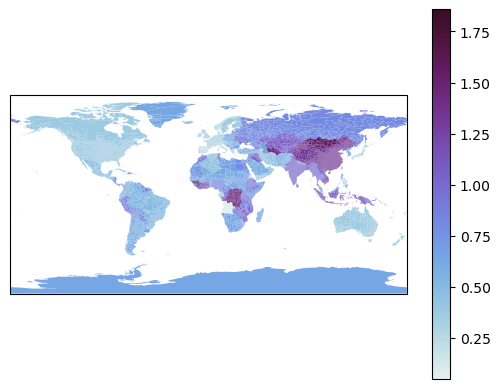

In [16]:
from funcs_plot import plot_map
import cmocean
plot_map(dgdp.sel(hierid=gdf.hierid.values).mean('idv'),
         gdf,cmap=cmocean.cm.dense,legend=True)

In [33]:
preds_tmp.sel(model='ACCESS-ESM1-5').exprun

<xarray.DataArray 'exprun' (exprun: 25)> Size: 200B
array(['ssp245r10i1p1f1', 'ssp245r11i1p1f1', 'ssp245r12i1p1f1',
       'ssp245r13i1p1f1', 'ssp245r14i1p1f1', 'ssp245r15i1p1f1',
       'ssp245r16i1p1f1', 'ssp245r17i1p1f1', 'ssp245r18i1p1f1',
       'ssp245r19i1p1f1', 'ssp245r1i1p1f1', 'ssp245r2i1p1f1', 'ssp245r3i1p1f1',
       'ssp245r4i1p1f1', 'ssp245r5i1p1f1', 'ssp245r6i1p1f1', 'ssp245r7i1p1f1',
       'ssp245r8i1p1f1', 'ssp245r9i1p1f1', 'ssp585r10i1p1f1', 'ssp585r1i1p1f1',
       'ssp585r2i1p1f1', 'ssp585r4i1p1f1', 'ssp585r5i1p1f1', 'ssp585r9i1p1f1'],
      dtype=object)
Coordinates:
  * exprun      (exprun) object 200B 'ssp245r10i1p1f1' ... 'ssp585r9i1p1f1'
    experiment  (exprun) object 200B dask.array<chunksize=(25,), meta=np.ndarray>
    run         (exprun) object 200B dask.array<chunksize=(25,), meta=np.ndarray>
    degree      int64 8B ...
    model       <U13 52B 'ACCESS-ESM1-5'

In [5]:
# Get filenames of aggregated climate predictors
fns = np.sort(glob.glob(f'{dir_list['proc']}aggs/{params_proc[proc]['varname']}_agg_*_{params_proc[proc]['geo_typ']}.zarr'))
if params_proc[proc]['popwght']:
    fns = [fn for fn in fns if re.search(r'\_popwght\.zarr',fn)]
else:
    fns = [fn for fn in fns if not re.search(r'\_popwght\.zarr',fn)]

def project_impact(ds,coeff_var = 'coeffs'):
    ''' Helper function for xr.map_blocks
    '''
    return (ds[coeff_var]*ds.tassumpoly).sum('pred',skipna=False)

# Load covariates with population
preds = xr.open_zarr(dir_list['proc']+'aux/all_preds.zarr')
# Get pop counts by ageset
agepops_tmp = preds.pop.sel(ageset = [age for age in preds.ageset.values if age != 'agetotal']).mean('year').load().chunk({'gwl':1})


fn = [fn for fn in fns if 'ACCESS-ESM1-5' in fn][0]
# Load climate data -------------
#--------------------------------
with warnings.catch_warnings():
    warnings.filterwarnings('ignore')
    # Ignore .done flag warning
    ds = xr.open_zarr(fn,consolidated=False,decode_timedelta=False)

# Make model/exprun dimension to match
ds['exprun'] = ds['experiment']+ds['run']
ds = ds.set_index(idv = ['model','exprun'])

if params_proc[proc]['varname'] == 'tassumpoly':
    ds['degree'] = [f'tassumpoly_{k}' for k in ds.degree.values]
    ds = ds.rename({'degree':'pred'})
elif params_proc[proc]['varname'] == 'tasmaxbinF':
    ds['binF'] = [f'tasmaxbinF_{k}' for k in ds.binF.values]
    ds = ds.rename({'binF':'pred'})
elif params_proc[proc]['varname'] == 'days90plus':
    ds = ds.rename({'binF':'pred'})
else:
    raise KeyError()

# Set location codes as they were originally generated
ds['poly_idx'] = gdf.hierid.values
ds = ds.rename({'poly_idx':'hierid'})
ds['hierid'] = ds['hierid'].astype(object) # Weird StringDTypeNan type issue otherwise below


In [6]:
with warnings.catch_warnings():
    # Suppressing for some reason a warning about deleting 
    # single levels of the idv multiindex (which as far as 
    # I can tell is not actually happening)
    warnings.filterwarnings('ignore')
    # Get mortality rate with changing climate and changing covars
    ds_tmp = xr.merge([coeffs_interacted.coeffs.sel(idv = ds.idv),
                       ds[params_proc[proc]['varname']]])
    ds[proc] = xr.map_blocks(project_impact,
                             ds_tmp.unify_chunks().reset_index('idv')) # (reset index because map_blocks has issues with MultiIndices)
    
    # Get mortality rate with constant climate and changing covars
    ds_tmp = xr.merge([coeffs_interacted.coeffs_ref.sel(idv = ds.idv),
                       ds[params_proc[proc]['varname']].sel(gwl=0.61,drop=True)])
    ds[proc+'_ref'] = xr.map_blocks(project_impact,
                                    ds_tmp.unify_chunks().reset_index('idv'),
                                    ['coeffs_ref'])

    # Recalculate total mortality rate (as weighted mean by 
    # age groups), taking into account population changes
    ds[['mortality','mortality_ref']].loc[{'ageset':'agetotal'}] = (ds[['mortality','mortality_ref']].sel(ageset = [age for age in preds.ageset.values if age != 'agetotal'])*agepops_tmp).sum('ageset',skipna=False) / agepops_tmp.sum('ageset',skipna=False)
   
    # Calculate change in impact vs. GWL0.61
    ds['d'+proc] = ds[proc] - ds[proc].sel(gwl=0.61)
    ds['d'+proc+'_ref'] = ds[proc+'_ref'] - ds[proc+'_ref'].sel(gwl=0.61)

    # Load model out
    ds_out = ds[['d'+proc,'d'+proc+'_ref']]

In [14]:
# Write metadata for variables
ds_out['d'+proc].attrs['long_name'] = 'Change in mortality (assuming SSP3 GDP, pop changes)'
ds_out['d'+proc+'_ref'].attrs['long_name'] = 'Change in mortality (assuming constant GWL0.61 climate and SSP3 GDP, pop changes)'

ds_out.loc[{'ageset':'agetotal'}] = (ds_out.sel(ageset = [age for age in preds.ageset.values if age != 'agetotal'])*agepops_tmp).sum('ageset',skipna=False) / agepops_tmp.sum('ageset',skipna=False)


/glade/derecho/scratch/schwarzwald/tmp/ipykernel_55257/1398716296.py:5: DeprecationWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  ds_out.loc[{'ageset':'agetotal'}] = (ds_out.sel(ageset = [age for age in preds.ageset.values if age != 'agetotal'])*agepops_tmp).sum('ageset',skipna=False) / agepops_tmp.sum('ageset',skipna=False)


(array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

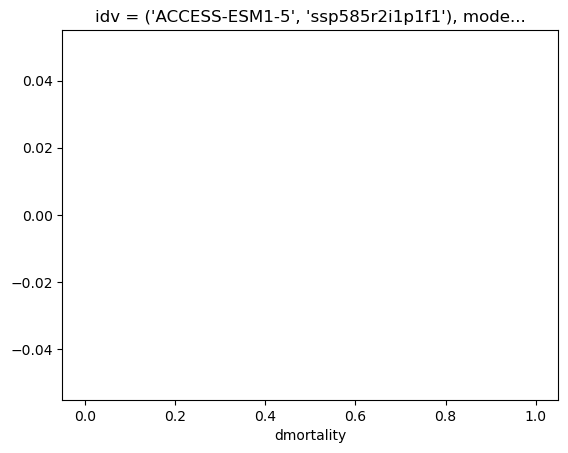

In [13]:
ds.isel(idv=-4).dmortality.plot.hist()

In [53]:
ds_tmp.hierid

<xarray.DataArray 'hierid' (hierid: 24378)> Size: 195kB
array(['ABW', 'AFG.1.12', 'AFG.1.R8abddb145b8788ee', ...,
       'ZWE.8.Raef3712f385d02bc', 'ZWE.9.46', 'ZWE.9.R19a261b63a503c9c'],
      shape=(24378,), dtype=object)
Coordinates:
  * hierid      (hierid) object 195kB 'ABW' ... 'ZWE.9.R19a261b63a503c9c'
    degree      int64 8B dask.array<chunksize=(), meta=np.ndarray>
    indflag     <U5 20B dask.array<chunksize=(), meta=np.ndarray>
    obstreat    <U3 12B dask.array<chunksize=(), meta=np.ndarray>
    resolution  <U6 24B dask.array<chunksize=(), meta=np.ndarray>
    spec        <U10 40B dask.array<chunksize=(), meta=np.ndarray>
    timeframe   <U9 36B dask.array<chunksize=(), meta=np.ndarray>

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

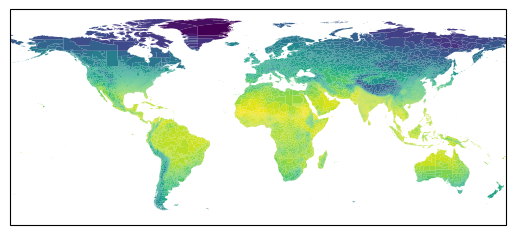

In [36]:
from funcs_plot import plot_map
plot_map(ds.tassumpoly.sel(gwl=2,pred='tassumpoly_1',hierid=gdf.hierid.values).mean(('idv','proj_base')),
         gdf)

In [ ]:
dgdp.isel(idv=0).sel(hierid=gdf.hierid.values).plot.hist

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

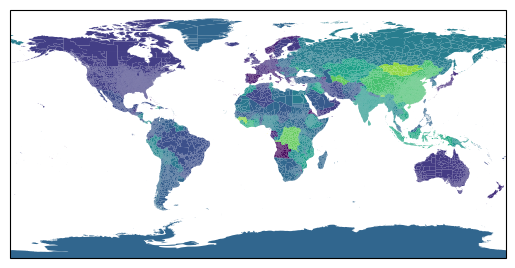

In [107]:
plot_map(dgdp.isel(idv=0).sel(hierid=gdf.hierid.values),
         gdf)

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

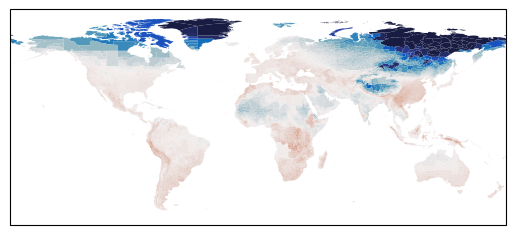

In [104]:
from funcs_plot import plot_map
import cmocean
plot_map(ds.dmortality_ref.sel(gwl=2,ageset='age5to64',pred_ssp='ssp3',pred_model='high',hierid=gdf.hierid.values).mean(('idv','proj_base')),
         gdf,vmin=-100,vmax=100,cmap=cmocean.cm.balance)

In [46]:
ds.dmortality.sel(gwl=2,ageset='agetotal',pred_ssp='ssp3',pred_model='high',hierid=gdf.hierid.values).mean(('idv','proj_base')).max().load()

<xarray.DataArray 'dmortality' ()> Size: 8B
array(35.20718306)
Coordinates:
    gwl         float64 8B 2.0
    ageset      <U8 32B 'agetotal'
    pred_ssp    <U4 16B 'ssp3'
    pred_model  <U4 16B 'high'
    obstreat    <U3 12B 'sep'
    degree      int64 8B 1
    indflag     <U5 20B 'noInd'
    resolution  <U6 24B '025deg'
    spec        <U10 40B 'interacted'
    timeframe   <U9 36B '1980-2010'
Attributes:
    DESCRIPTION:  Population, per-capita GDP, and long-run climate variables ...
    SOURCE:       create_pred_dataset.ipynb

In [36]:
import geopandas as gpd
from funcs_plot import plot_map
import cmocean
gdf = gpd.read_file('../aux_data/geo_data/impact-region.shp')
gdf['geometry'] = gdf['geometry'].make_valid()
#gdf['geometry'] = gdf['geometry'].set_crs('EPSG:4326')

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../aux_data/geo_data/impact-region.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


In [43]:
a = ds_out.sel(gwl=3,ageset='agetotal',proj_base='ERA5').isel(pred_ssp=0,pred_model=0).mean('idv').load()

In [45]:
b = (a.dmortality - a.dmortality_ref)

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

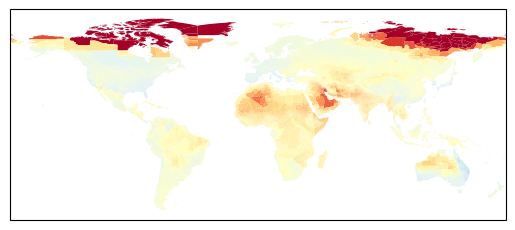

In [46]:
plot_map(b.sel(hierid=gdf.hierid.values),
         gdf,vmin=-500,vmax=500,cmap='RdYlBu_r')

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

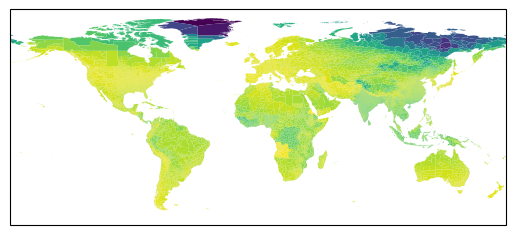

In [92]:
plot_map(a.dmortality.sel(hierid=gdf.hierid.values),
         gdf)

In [73]:
a = preds_tmp.isel(pred_ssp=0,pred_model=0,proj_base=0).load()

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

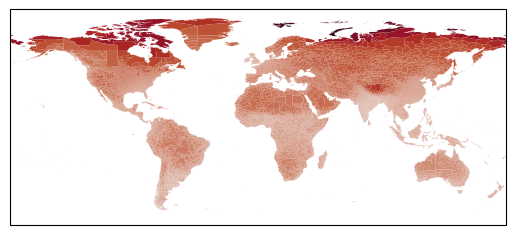

In [21]:
plot_map((a.sel(gwl=2) - a.sel(gwl=0.61)).mean('idv').covars.sel(covar='lrtavg',hierid=gdf.hierid.values),
         gdf,
         vmin=-5,vmax=5,cmap=cmocean.cm.balance)

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

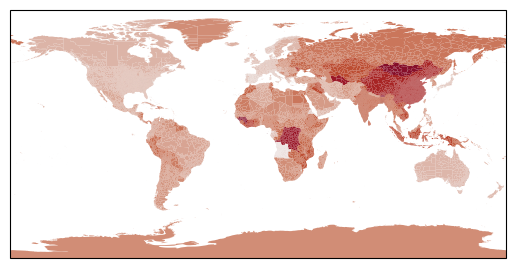

In [24]:
plot_map((a.sel(gwl=2) - a.sel(gwl=0.61)).mean('idv').covars.sel(covar='lgdppc',hierid=gdf.hierid.values),
         gdf,
         vmin=-2,vmax=2,cmap=cmocean.cm.balance)

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

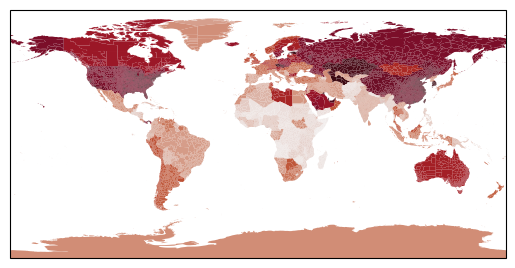

In [18]:
plot_map(((preds.sel(gwl=2) - preds.sel(gwl=0.61)).gdppc.isel(pred_ssp = 0,pred_model = 0)).sel(hierid=gdf.hierid.values),
         gdf,cmap=cmocean.cm.balance,vmin=-20000,vmax=20000)

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

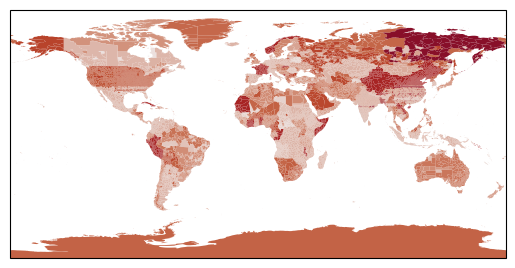

In [311]:
plot_map((a.sel(gwl=2) - a.sel(gwl=0.61)).mean('idv').covars.sel(covar='lgdppc'),
         gdf,
         vmin=-2,vmax=2,cmap=cmocean.cm.balance)

(array([8.2254e+04, 4.1174e+04, 3.2617e+04, 1.5830e+04, 1.8835e+04,
        3.5440e+03, 7.4000e+02, 1.1000e+01, 9.0000e+00, 1.0000e+01]),
 array([3.14712878e-02, 1.31443722e+01, 2.62572730e+01, 3.93701739e+01,
        5.24830748e+01, 6.55959757e+01, 7.87088765e+01, 9.18217774e+01,
        1.04934678e+02, 1.18047579e+02, 1.31160480e+02]),
 <BarContainer object of 10 artists>)

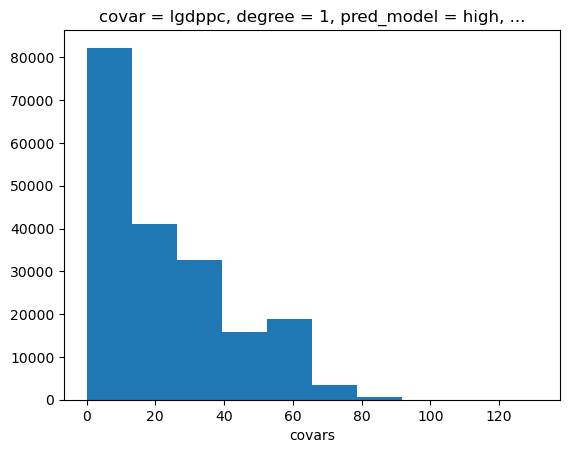

In [307]:
(np.exp(a.mean('idv').covars.sel(covar='lgdppc'))/1000).plot.hist()

(array([8.612e+03, 7.424e+03, 2.347e+03, 2.878e+03, 2.903e+03, 2.040e+02,
        6.000e+00, 0.000e+00, 2.000e+00, 2.000e+00]),
 array([6.14269327e-02, 1.28736270e+01, 2.56858270e+01, 3.84980271e+01,
        5.13102271e+01, 6.41224271e+01, 7.69346272e+01, 8.97468272e+01,
        1.02559027e+02, 1.15371227e+02, 1.28183427e+02]),
 <BarContainer object of 10 artists>)

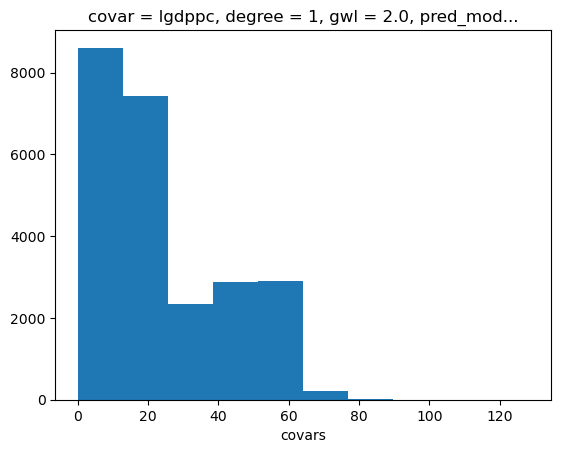

In [305]:
(np.exp(a.sel(gwl=2)).mean('idv').covars.sel(covar='lgdppc')/1000).plot.hist()

(array([3149., 7488., 3000., 2635., 6149., 1324.,  410.,  135.,   29.,
          59.]),
 array([  117.35163983,  5840.99257087, 11564.6335019 , 17288.27443294,
        23011.91536397, 28735.556295  , 34459.19722604, 40182.83815707,
        45906.47908811, 51630.12001914, 57353.76095018]),
 <BarContainer object of 10 artists>)

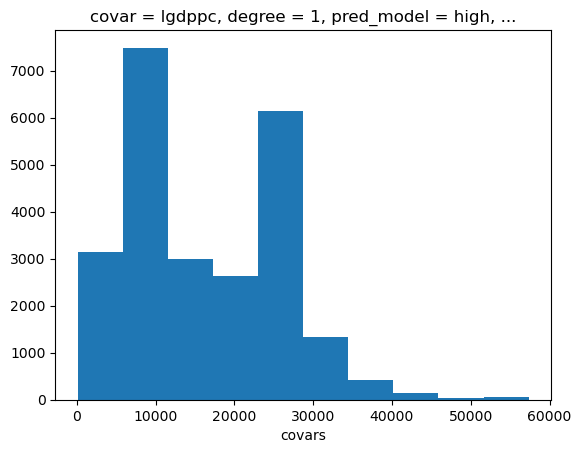

In [308]:
(np.exp(a.sel(gwl=4)) - np.exp(a.sel(gwl=0.61))).mean('idv').covars.sel(covar='lgdppc').plot.hist()

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

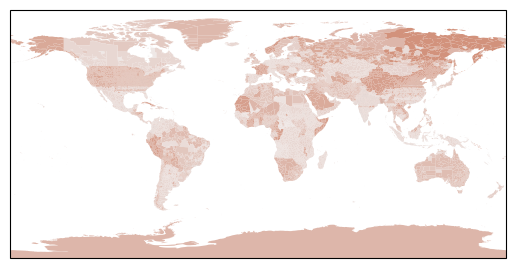

In [297]:
plot_map((a.sel(gwl=2) - a.sel(gwl=0.61)).mean('idv').covars.sel(covar='lgdppc'),
         gdf,
         vmin=-5,vmax=5,cmap=cmocean.cm.balance)

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

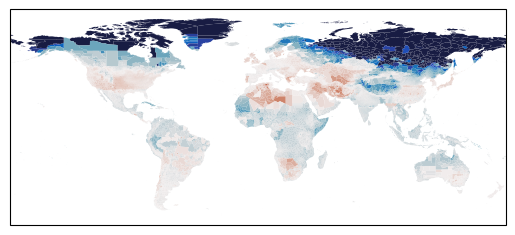

In [284]:
from funcs_plot import plot_map
import cmocean
plot_map(ds.dmortality.sel(gwl=1,ageset='agetotal',proj_base='ERA5').isel(pred_ssp=0,pred_model=0).mean('idv'),
         gdf,vmin=-200,vmax=200,cmap=cmocean.cm.balance)

In [ ]:
for fn in tqdm(fns):
    output_fn = f'{dir_list['proc']}impact_projs/{proc}/{re.sub(params_proc[proc]['varname'],f'd{proc}-interacted',re.split(r'\/',fn)[-1])}'
    
    if overwrite or (not os.path.exists(output_fn)):
        
        # Load aggregated climate predictor
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore')
            # Ignore .done flag warning
            ds = xr.open_zarr(fn,consolidated=False,decode_timedelta=False)
    
        # Isolate predictor variables
        if params_proc[proc]['varname'] == 'tassumpoly':
            ds['degree'] = [f'tassumpoly_{k}' for k in ds.degree.values]
            ds = ds.rename({'degree':'pred'})
        elif params_proc[proc]['varname'] == 'tasmaxbinF':
            ds['binF'] = [f'tasmaxbinF_{k}' for k in ds.binF.values]
            ds = ds.rename({'binF':'pred'})
        elif params_proc[proc]['varname'] == 'days90plus':
            ds = ds.rename({'binF':'pred'})
        else:
            raise KeyError()
    
        # Calculate impact from linear regression model
        ds[proc] = (coeffs_interacted.coeffs*ds[params_proc[proc]['varname']]).sum('pred',skipna=False)
        # Calculate change in impact vs. GWL0.61
        ds['d'+proc] = ds[proc] - ds[proc].sel(gwl=0.61)

        # Add max gwl to coordinates, for referece
        ds = ds.assign_coords({'maxgwl':(('idv'),ds.gwl.isel(gwl=np.array([(g-1) if g != 0 else -1 
                                                          for g in (np.isnan(ds['d'+proc]).
                                                                    argmax('gwl').
                                                                    max([d for d in ds['d'+proc].sizes if d not in ['gwl','idv']])).
                                                                    load()])).values)})
        # Make sure all-nan idvs are all-nan in maxgwl
        ds['maxgwl'] = ds.maxgwl.where(~np.isnan(ds['d'+proc]).all([d for d in ds['d'+proc].sizes if d != 'idv']).load())
    
        # Prepare output 
        ds_out = ds[['locid','d'+proc]]
        ds_out.attrs = {'SOURCE':'project_impacts.ipynb',
                'DESCRIPTION':f'changes in {proc}, at the {params_proc[proc]['geo_typ']} level',
                'pop_weighted':params_proc[proc]['popwght']}
    
        # Export
        with warnings.catch_warnings():
            # Catches a Zarr v3 error related to string coordinates saved 
            # as objects instead of strings, I believe
            warnings.filterwarnings('ignore')
            utility_save(ds_out,output_fn,zarr_mode='w',save_kwargs = {'zarr_format':3,'consolidated':False})
    else:
        print(output_fn+' exists, skipped!')